<h1>Pytorch Convolutional Autoencoder</h1>


Importing libraries:

In [ ]:
import torch
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
%matplotlib inline
import torch.nn as nn
import torch.nn.functional as F

print(torch.__version__)
!python --version

2.1.0+cu118
Python 3.10.12


Loading datasets and creating dataloaders:

In [ ]:
# convert data to torch.FloatTensor
transform = transforms.ToTensor()

# load the training and test datasets
train_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=True, download=True, transform=transform)

In [ ]:
# Create training and test dataloaders
num_workers = 0
# how many samples per batch to load
batch_size = 500

# prepare data loaders
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, num_workers=num_workers)
print(train_data)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /root/.pytorch/MNIST_data/
    Split: Train
    StandardTransform
Transform: ToTensor()


Visualize the data


torch.Size([500, 1, 28, 28])


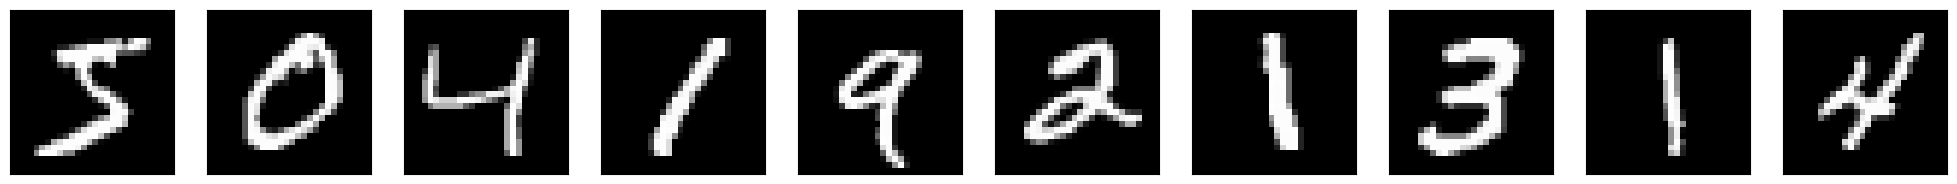

In [ ]:
# obtain one batch of training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
print(images.shape)

n = 10
plt.figure(figsize=(25, 4))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    plt.imshow(np.squeeze(images[i]), cmap='gray')

plt.show()

Building the Encode-Decode network


In [ ]:
class CAE_Encoder(nn.Module):
    def __init__(self):
        super(CAE_Encoder, self).__init__()
        ## encoder layers ##
        # conv layer (depth from 1 --> 16), 3x3 kernels
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        # conv layer (depth from 16 --> 4), 3x3 kernels
        self.conv2 = nn.Conv2d(16, 4, 3, padding=1)
        # pooling layer to reduce x-y dims by two; kernel and stride of 2
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        ## encode ##
        # add hidden layers with relu activation function
        # and maxpooling after
        #print('Encoding:', x.shape)
        x = self.conv1(x)
        #print('after conv1:', x.shape)
        x = F.relu(x)
        #print('after relu1:', x.shape)
        x = self.pool(x)
        #print('after max pooling 1:', x.shape)
        # add second hidden layer
        x = self.conv2(x)
        #print('after conv2:', x.shape)
        x = F.relu(x)
        #print('after relu2:', x.shape)
        x = self.pool(x)  # compressed representation
        #print('after max pooling 2:', x.shape)
        return x

enc_model = CAE_Encoder()
print(enc_model)
print(list(enc_model.parameters())[0].size())

CAE_Encoder(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
torch.Size([16, 1, 3, 3])


In [ ]:
class CAE_Decoder(nn.Module):
    def __init__(self):
        super(CAE_Decoder, self).__init__()

        ## decoder layers ##
        ## a kernel of 2 and a stride of 2 will increase the spatial dims by 2
        self.t_conv1 = nn.ConvTranspose2d(4, 16, 2, stride=2)
        self.t_conv2 = nn.ConvTranspose2d(16, 1, 2, stride=2)


    def forward(self, x):

        ## decode ##
        # add transpose conv layers, with relu activation function
        #print('Decoding')
        x = self.t_conv1(x)
        #print('after t_conv 1:', x.shape)
        x = F.relu(x)
        #print('after relu3:', x.shape)
        # output layer (with sigmoid for scaling from 0 to 1)
        x = self.t_conv2(x)
        #print('after t_conv 2:', x.shape)
        x = F.sigmoid(x)
        #print('after sigmoid:', x.shape)
        return x

dec_model = CAE_Decoder()
print(dec_model)
print(list(dec_model.parameters())[0].size())

CAE_Decoder(
  (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
  (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
)
torch.Size([4, 16, 2, 2])


In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self):
        super(AutoEncoder, self).__init__()

        # generate two NN, for decoder and encoder operations
        self.encoder = CAE_Encoder()
        self.decoder = CAE_Decoder()

        self.train_line = nn.Sequential(self.encoder, self.decoder)

    # forward propagation (encode + decode)
    def forward(self, x):
        return self.train_line(x)

    # encode data to reduced dimensionality form
    def encode(self,x):
        return self.encoder(x)

    # decode reduced dimensionality data
    def decode(self,x):
        return self.decoder(x)


Configure and train the model


In [ ]:
model = AutoEncoder()
print(model)
print(list(model.parameters())[0].size())

# specify loss function
criterion = nn.MSELoss()

# specify loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

AutoEncoder(
  (encoder): CAE_Encoder(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): CAE_Decoder(
    (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
    (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
  )
  (train_line): Sequential(
    (0): CAE_Encoder(
      (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): CAE_Decoder(
      (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
      (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
    )
  )
)
torch.Size([16, 1, 3, 3])


In [ ]:
# number of epochs to train the model
n_epochs = 25

for epoch in range(1, n_epochs+1):
    # monitor training loss
    train_loss = 0.0

    ###################
    # train the model #
    ###################
    for data in train_loader:
        # _ stands in for labels, here
        # no need to flatten images
        images, _ = data
        # clear the gradients of all optimized variables
        optimizer.zero_grad()
        # forward pass: compute predicted outputs by passing inputs to the model
        outputs = model(images)
        # calculate the loss
        loss = criterion(outputs, images)
        # update running training loss
        train_loss += loss.item()
        # backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        # perform a single optimization step (parameter update)
        optimizer.step()

    # print avg training statistics
    train_loss = train_loss/len(train_loader)
    print('Epoch: {} \tTraining Loss: {:.6f}'.format(epoch,train_loss))

#Saving the model and training parameters

#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_location = '/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks'
torch.save(model, base_location + '/Pytorch/MNIST_CAE/CAE_Model.pt')

Epoch: 1 	Training Loss: 0.163783
Epoch: 2 	Training Loss: 0.057081
Epoch: 3 	Training Loss: 0.043670
Epoch: 4 	Training Loss: 0.029463
Epoch: 5 	Training Loss: 0.026407
Epoch: 6 	Training Loss: 0.024675
Epoch: 7 	Training Loss: 0.023554
Epoch: 8 	Training Loss: 0.022723
Epoch: 9 	Training Loss: 0.022028
Epoch: 10 	Training Loss: 0.021418
Epoch: 11 	Training Loss: 0.020846
Epoch: 12 	Training Loss: 0.020282
Epoch: 13 	Training Loss: 0.019689
Epoch: 14 	Training Loss: 0.019038
Epoch: 15 	Training Loss: 0.018280
Epoch: 16 	Training Loss: 0.017690
Epoch: 17 	Training Loss: 0.017205
Epoch: 18 	Training Loss: 0.016772
Epoch: 19 	Training Loss: 0.016402
Epoch: 20 	Training Loss: 0.016080
Epoch: 21 	Training Loss: 0.015795
Epoch: 22 	Training Loss: 0.015541
Epoch: 23 	Training Loss: 0.015313
Epoch: 24 	Training Loss: 0.015106
Epoch: 25 	Training Loss: 0.014915
Mounted at /content/drive


Testing the Encoder part with whole test dataset to compare with cFS


In [ ]:
#importing libraries
import torch
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import time
from psutil import *

In [ ]:
#Getting CPU resources
print("CPU's: {}".format(cpu_count()))
print(cpu_stats())
!cat /proc/cpuinfo
print(virtual_memory())

CPU's: 2
scpustats(ctx_switches=19394728, interrupts=14904968, soft_interrupts=9154955, syscalls=0)
processor	: 0
vendor_id	: AuthenticAMD
cpu family	: 23
model		: 49
model name	: AMD EPYC 7B12
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2249.998
cache size	: 512 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ht syscall nx mmxext fxsr_opt pdpe1gb rdtscp lm constant_tsc rep_good nopl nonstop_tsc cpuid extd_apicid tsc_known_freq pni pclmulqdq ssse3 fma cx16 sse4_1 sse4_2 movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm cmp_legacy cr8_legacy abm sse4a misalignsse 3dnowprefetch osvw topoext ssbd ibrs ibpb stibp vmmcall fsgsbase tsc_adjust bmi1 avx2 smep bmi2 rdseed adx smap clflushopt clwb sha_ni xsaveopt xsavec xgetbv1 clzero xsaveerptr arat npt nrip_save umip rdpid
bugs		

In [ ]:
#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
base_location = '/content/drive/My Drive/Academico/CienciasEspaciales/WVU/Research/NeuralNetworks'

#Load model definition before

#Loading the saved model
model = torch.load(base_location + '/Pytorch/MNIST_CAE/CAE_Model.pt',)
model.eval()

Mounted at /content/drive


AutoEncoder(
  (encoder): CAE_Encoder(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): CAE_Decoder(
    (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
    (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
  )
  (train_line): Sequential(
    (0): CAE_Encoder(
      (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): CAE_Decoder(
      (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
      (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
    )
  )
)

In [ ]:
batch_size = 700
num_workers = 0
transform = transforms.ToTensor()
# prepare test data loader
test_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, num_workers=num_workers)
print(test_data)

elapsed = []
latency = 0.0
throughput = 0.0

#starter, ender = torch.cuda.Event(enable_timing=True),torch.Event(enable_timing=True)
#starter.cuda.record()
#ender.cuda.record()
#torch.cuda.synchronize()


with torch.no_grad():
  cpu_start = Process().cpu_percent()
  for data in test_loader:
      images, _ = data
      start = time.time()
      latent = model.encode(images)
      end = time.time()
      elapsed.append((end - start)/images.size(0))
  cpu_end = Process().cpu_percent()

latency = np.sum(elapsed)/len(test_loader)
lat_std = np.std(elapsed);
throughput = 1/latency;
cpu_usage = cpu_end - cpu_start
print('Latency: {:.6f}, Latency Std Dev: {:.6f}, Throughput: {:.2f}, CPU usage {:.6f}'.format(latency,lat_std,throughput,cpu_usage))

Dataset MNIST
    Number of datapoints: 10000
    Root location: /root/.pytorch/MNIST_data/
    Split: Test
    StandardTransform
Transform: ToTensor()
Latency: 0.000086, Latency Std Dev: 0.000002, Throughput: 11591.16, CPU usage 0.000000


Testing the complete Autoencoder with one batch

torch.Size([100, 4, 7, 7])
tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]],

        [[5.7510, 5.7510, 5.7510, 5.7510, 5.7510, 5.7510, 5.7510],
         [6.3060, 6.8741, 3.9675, 5.1228, 5.2015, 5.2148, 5.6805],
         [6.3463, 8.0803, 7.6305, 7.3514, 7.1397, 0.5861, 5.6473],
         [5.7513, 5.7583, 5.9779, 7.7300, 6.8050, 5.6089, 5.8437],
         [5.7510, 5.7510, 6.2449, 7.2563, 1.5394, 5.9111, 5.7510],
         [5.7510, 5.8747, 7.1160, 3.4713, 5.8437, 5.8710, 5.7510],
         [5.7510, 6.2197, 7.4500, 0.8493, 5.8101, 5.7510, 5.7510]],

        [[6.6828, 6.6828, 6.682

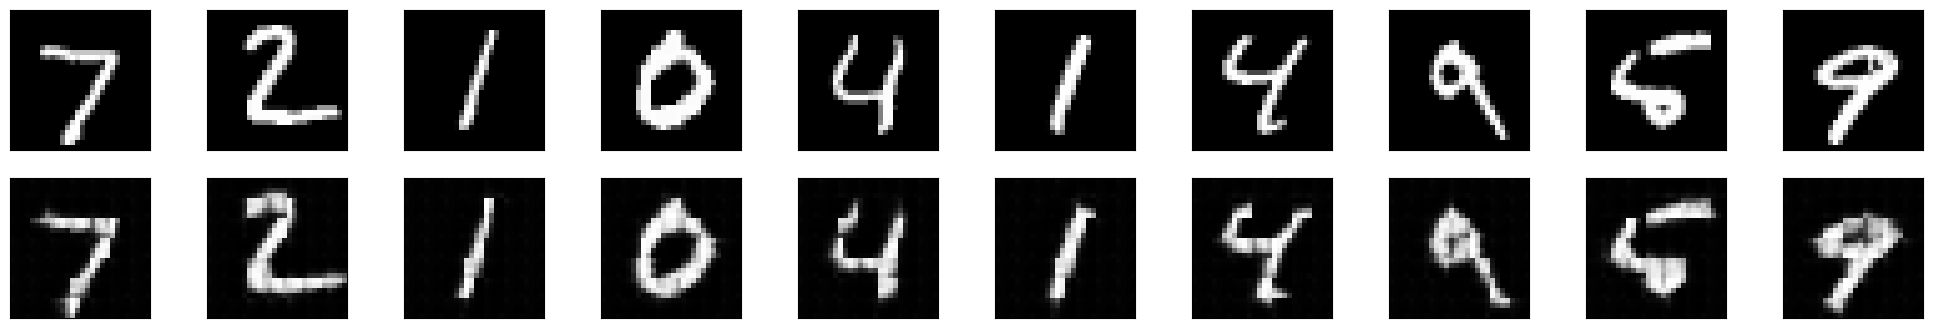

In [ ]:
# obtain one batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)

latent = model.encode(images)
print(latent.shape)
print(latent[0])

# get sample outputs
output = model.decode(latent)
print(output.shape)

# execute all encode-decode process instead
#output = model(images)

# prep images for display
images = images.numpy()

# output is resized into a batch of images
output = output.view(batch_size, 1, 28, 28)
# use detach when it's an output that requires_grad
output = output.detach().numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

Saving the Model as Pytorch script, and run it

torch.Size([100, 4, 7, 7])
tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]],

        [[5.7510, 5.7342, 5.0970, 4.7281, 4.4025, 5.2264, 5.7510],
         [5.7510, 8.5486, 4.2902, 3.2765, 2.8763, 3.5462, 5.7510],
         [5.7510, 8.3924, 6.9846, 4.5013, 3.0005, 3.5063, 5.7510],
         [5.6787, 6.5070, 6.5878, 3.5899, 2.7654, 2.1472, 5.6473],
         [8.6923, 6.4414, 2.9476, 5.0426, 4.7554, 1.1619, 5.6473],
         [7.7673, 9.7621, 6.8201, 3.2653, 4.8171, 5.9046, 5.8075],
         [5.8426, 6.9347, 7.5818, 7.2773, 5.7761, 5.8312, 5.7510]],

        [[6.6828, 6.8013, 8.029

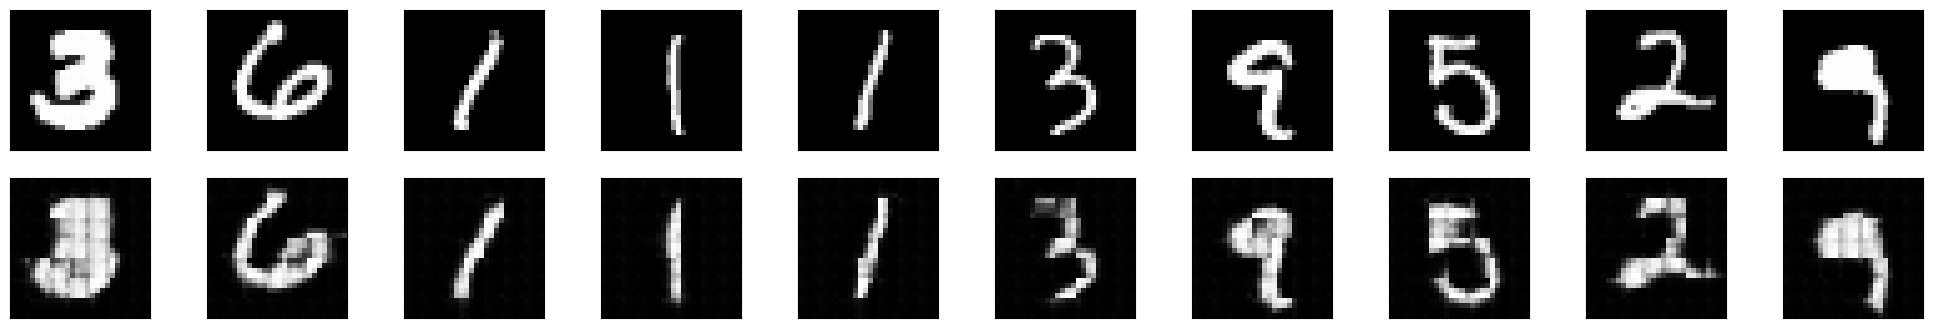

In [ ]:
#obtain one batch of test images
images, labels = next(dataiter)

#saving the encoder model as a pt script
traced_script = torch.jit.trace(model.encoder, images)
traced_script.save(base_location + '/Pytorch/MNIST_CAE/Encoder_model.pt')

#getting the latent vector through the script
latent_output = traced_script(images)
print(latent_output.shape)
print(latent_output[0])

#decode the latent vector using the original decoder model
output = model.decode(latent_output)
print(output.shape)
images = images.numpy()

output = output.view(batch_size, 1, 28, 28)
output = output.detach().numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)